In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt
import json
from sklearn.utils.class_weight import compute_class_weight

In [2]:
# 1. Load data
# -----------------------------------------------------------------
train_df = pd.read_csv(r"C:\Users\Lenovo\Desktop\CattleBreedClean\cat_train.csv")
val_df   = pd.read_csv(r"C:\Users\Lenovo\Desktop\CattleBreedClean\cat_val.csv")
test_df  = pd.read_csv(r"C:\Users\Lenovo\Desktop\CattleBreedClean\cat_test.csv")

train_df['breed'] = train_df['breed'].astype(str)
val_df['breed']   = val_df['breed'].astype(str)
test_df['breed']  = test_df['breed'].astype(str)

NUM_CLASSES = train_df['breed'].nunique()
print(f"Number of classes: {NUM_CLASSES}")
print(train_df['breed'].value_counts())

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

Number of classes: 10
breed
Sahiwal              595
Hallikar             299
Red_Sindhi           282
Malnad_gidda         248
Gir                  245
Holstein_Friesian    229
Amritmahal           206
Murrah               175
Jersey               175
Kasargod             175
Name: count, dtype: int64


In [3]:
# -----------------------------------------------------------------
# 2. Data generators (heavier augmentation)
# -----------------------------------------------------------------
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.2,
    shear_range=0.1,
    brightness_range=[0.8, 1.2],
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='breed',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)

val_gen = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='breed',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_gen = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='image_path',
    y_col='breed',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

class_indices = train_gen.class_indices
idx_to_class = {v: k for k, v in class_indices.items()}
print("Class mapping:", class_indices)

with open(r"C:\Users\Lenovo\Desktop\CattleBreedClean\class_indices.json", "w") as f:
    json.dump(class_indices, f, indent=2)

Found 2629 validated image filenames belonging to 10 classes.
Found 563 validated image filenames belonging to 10 classes.
Found 564 validated image filenames belonging to 10 classes.
Class mapping: {'Amritmahal': 0, 'Gir': 1, 'Hallikar': 2, 'Holstein_Friesian': 3, 'Jersey': 4, 'Kasargod': 5, 'Malnad_gidda': 6, 'Murrah': 7, 'Red_Sindhi': 8, 'Sahiwal': 9}


In [8]:
# -----------------------------------------------------------------
# 3. Class weights (fixes imbalance)
# -----------------------------------------------------------------
classes = np.array(list(class_indices.values()))
labels = train_df['breed'].map(class_indices).values
class_weights = compute_class_weight('balanced', classes=classes, y=labels)
class_weight_dict = dict(zip(classes, class_weights))
print(class_weight_dict)
print(len(class_weight_dict))
print(sorted(class_weight_dict.keys()))
print(class_indices)
print(train_df['breed'].map(class_indices).isna().sum())  # should be 0

{np.int64(0): np.float64(1.2762135922330098), np.int64(1): np.float64(1.073061224489796), np.int64(2): np.float64(0.8792642140468228), np.int64(3): np.float64(1.1480349344978167), np.int64(4): np.float64(1.5022857142857142), np.int64(5): np.float64(1.5022857142857142), np.int64(6): np.float64(1.0600806451612903), np.int64(7): np.float64(1.5022857142857142), np.int64(8): np.float64(0.9322695035460993), np.int64(9): np.float64(0.44184873949579834)}
10
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
{'Amritmahal': 0, 'Gir': 1, 'Hallikar': 2, 'Holstein_Friesian': 3, 'Jersey': 4, 'Kasargod': 5, 'Malnad_gidda': 6, 'Murrah': 7, 'Red_Sindhi': 8, 'Sahiwal': 9}
0


In [9]:
import os

surti_rows = train_df[train_df['breed'] == 'Surti']
print(f"Surti rows in train_df: {len(surti_rows)}")

missing = 0
for p in surti_rows['image_path']:
    if not os.path.exists(p):
        missing += 1
        print("MISSING:", p)
print(f"Missing files: {missing} / {len(surti_rows)}")

Surti rows in train_df: 0
Missing files: 0 / 0


In [10]:
print(train_df['breed'].nunique())  # should print 10

10


In [11]:
print(val_df['breed'].nunique(), val_df['breed'].unique())
print(test_df['breed'].nunique(), test_df['breed'].unique())

10 <StringArray>
[              'Gir',          'Kasargod',           'Sahiwal',
 'Holstein_Friesian',          'Hallikar',        'Amritmahal',
            'Murrah',        'Red_Sindhi',            'Jersey',
      'Malnad_gidda']
Length: 10, dtype: str
10 <StringArray>
[     'Malnad_gidda',               'Gir',        'Red_Sindhi',
          'Hallikar',           'Sahiwal',            'Murrah',
          'Kasargod', 'Holstein_Friesian',        'Amritmahal',
            'Jersey']
Length: 10, dtype: str


In [12]:
val_df = val_df[val_df['breed'] != 'Surti'].reset_index(drop=True)
test_df = test_df[test_df['breed'] != 'Surti'].reset_index(drop=True)

In [13]:
# -----------------------------------------------------------------
# 4. Build model (stronger regularization)
# -----------------------------------------------------------------
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x = Dropout(0.5)(x)
output = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
# 5. Stage 1 training (frozen base)
# -----------------------------------------------------------------
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint(
    r"C:\Users\Lenovo\Desktop\CattleBreedClean\best_model_stage1.keras",
    monitor='val_accuracy', save_best_only=True
)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
EPOCHS_STAGE1 = 100

history1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_STAGE1,
    callbacks=[early_stop, checkpoint, reduce_lr],
    class_weight=class_weight_dict,
    verbose=2
)

Epoch 1/100
83/83 - 164s - 2s/step - accuracy: 0.3332 - loss: 2.0275 - val_accuracy: 0.5400 - val_loss: 1.5751 - learning_rate: 0.0010
Epoch 2/100
83/83 - 103s - 1s/step - accuracy: 0.4758 - loss: 1.6426 - val_accuracy: 0.5968 - val_loss: 1.4496 - learning_rate: 0.0010
Epoch 3/100
83/83 - 102s - 1s/step - accuracy: 0.5245 - loss: 1.5201 - val_accuracy: 0.6341 - val_loss: 1.3539 - learning_rate: 0.0010
Epoch 4/100
83/83 - 101s - 1s/step - accuracy: 0.5630 - loss: 1.4516 - val_accuracy: 0.6785 - val_loss: 1.3171 - learning_rate: 0.0010
Epoch 5/100
83/83 - 110s - 1s/step - accuracy: 0.5690 - loss: 1.4204 - val_accuracy: 0.6679 - val_loss: 1.2773 - learning_rate: 0.0010
Epoch 6/100
83/83 - 100s - 1s/step - accuracy: 0.5888 - loss: 1.3887 - val_accuracy: 0.6572 - val_loss: 1.2734 - learning_rate: 0.0010
Epoch 7/100
83/83 - 97s - 1s/step - accuracy: 0.6162 - loss: 1.3408 - val_accuracy: 0.6945 - val_loss: 1.2275 - learning_rate: 0.0010
Epoch 8/100
83/83 - 99s - 1s/step - accuracy: 0.6227 - l

In [15]:
# -----------------------------------------------------------------
# 6. Stage 2: Fine-tune (unfreeze last 15 layers)
# -----------------------------------------------------------------
base_model.trainable = True
for layer in base_model.layers[:-15]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

checkpoint2 = ModelCheckpoint(
    r"C:\Users\Lenovo\Desktop\CattleBreedClean\best_model_final.keras",
    monitor='val_accuracy', save_best_only=True, mode='max'
)
early_stop_stage2 = EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, mode='max')
reduce_lr_stage2 = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7)

EPOCHS_STAGE2 = 100

history2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_STAGE2,
    callbacks=[early_stop_stage2, checkpoint2, reduce_lr_stage2],
    class_weight=class_weight_dict
)


Epoch 1/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.6801 - loss: 1.1998 - val_accuracy: 0.7851 - val_loss: 1.0532 - learning_rate: 1.0000e-05
Epoch 2/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 113s 1s/step - accuracy: 0.7022 - loss: 1.1723 - val_accuracy: 0.7904 - val_loss: 1.0557 - learning_rate: 1.0000e-05
Epoch 3/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - accuracy: 0.7219 - loss: 1.1488 - val_accuracy: 0.7869 - val_loss: 1.0553 - learning_rate: 1.0000e-05
Epoch 4/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.7372 - loss: 1.1206 - val_accuracy: 0.7815 - val_loss: 1.0626 - learning_rate: 1.0000e-05
Epoch 5/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.7238 - loss: 1.1215 - val_accuracy: 0.7815 - val_loss: 1.0595 - learning_rate: 5.0000e-06
Epoch 6/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.7375 - loss: 1.1101 - val_accuracy: 0.7869 - val_loss: 1.0527 - learning_rate: 5.0000e-06
Epoch 7/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 

In [16]:
# 7. Evaluate
# -----------------------------------------------------------------
test_loss, test_acc = model.evaluate(test_gen)
print(f"\n✅ Test Accuracy: {test_acc*100:.2f}%")
print(f"✅ Test Loss: {test_loss:.4f}")

18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.7801 - loss: 1.0623

✅ Test Accuracy: 78.01%
✅ Test Loss: 1.0623


In [17]:
# 8. Save final model
# -----------------------------------------------------------------
model.save(r"C:\Users\Lenovo\Desktop\CattleBreedClean\cattle_breed_mobilenetv2_final.keras")
print("\n✅ Model saved!")


✅ Model saved!


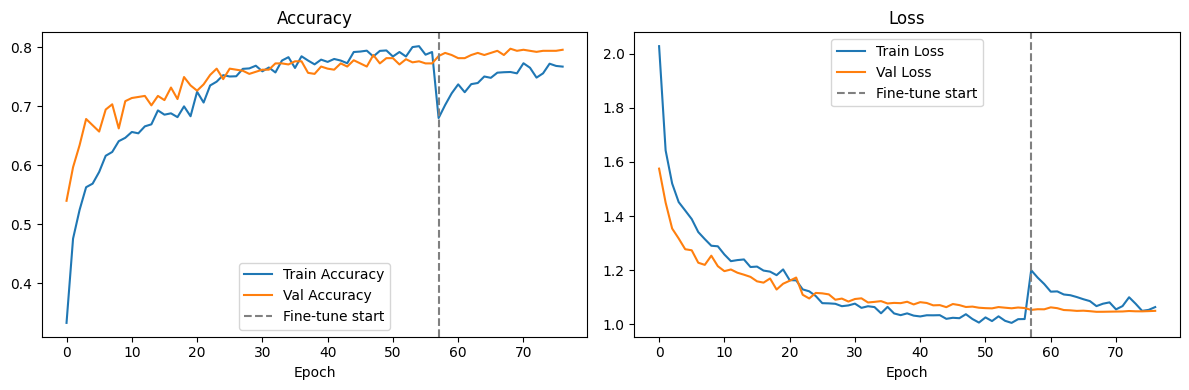


✅ Training complete. All artifacts saved to C:\Users\Lenovo\Desktop\CattleBreedClean\


In [18]:

# -----------------------------------------------------------------
# 9. Plot training curves
# -----------------------------------------------------------------
def combine_history(h1, h2, key):
    return h1.history[key] + h2.history[key]

acc = combine_history(history1, history2, 'accuracy')
val_acc = combine_history(history1, history2, 'val_accuracy')
loss = combine_history(history1, history2, 'loss')
val_loss = combine_history(history1, history2, 'val_loss')

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Val Accuracy')
plt.axvline(x=len(history1.history['accuracy']), color='gray', linestyle='--', label='Fine-tune start')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--', label='Fine-tune start')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.savefig(r"C:\Users\Lenovo\Desktop\CattleBreedClean\training_curves.png")
plt.show()

print("\n✅ Training complete. All artifacts saved to C:\\Users\\Lenovo\\Desktop\\CattleBreedClean\\")